# COU 07506 DIGITAL SIGNAL PROCESSING

## WEEK_01 — LAB 0
### Setting Up the DSP Laboratory

**Name:** ALPHONCE, ASIMWE MANYUSI

**Registration Number:** 240242437697

**Class:** BENG24COE

**Group no.:** 1

**Date:** 23 November 2026

**Instructor checkpoints:**
- [ ] Checkpoint 1
- [ ] Checkpoint 2

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP environment is ready!")

DSP environment is ready!


# LAB 0: PRE-LABORATORY EXERCISE

## Question 1

**List three devices used in everyday life that apply Digital Signal Processing (DSP), and identify one signal processed by each device.**

## Answer

1. **Digital Camera:** Processes image signals to improve picture quality, adjust brightness, and reduce image noise.

2. **Laptop Computer:** Processes audio signals through its sound system during video calls and music playback.

3. **GPS Navigation Device:** Processes satellite radio signals to determine the user's location and provide navigation information.

These devices use Digital Signal Processing to analyze, modify, and improve signals for different everyday applications.

## Task 1.1 — Generation of Basic Discrete-Time Signals

### Objective

The objective of this task is to generate and visualize four basic discrete-time signals using Python: the unit impulse, unit step, ramp, and exponential signals.

These signals are defined as follows:

- Unit impulse: δ(n) = 1 when n = 0, otherwise 0.
- Unit step: u(n) = 1 when n ≥ 0, otherwise 0.
- Ramp: r(n) = n u(n).
- Exponential: x(n) = (0.8)^n u(n).

### Python Implementation

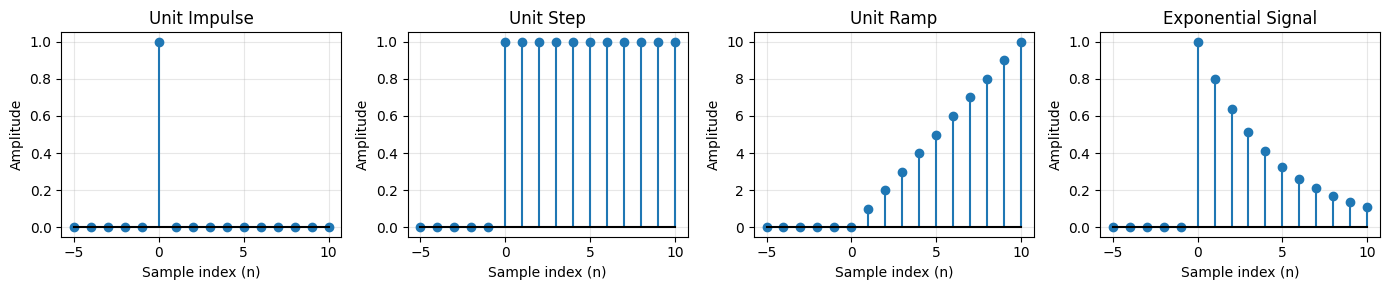

In [18]:

n = np.arange(-5, 11)

# Generate the signals
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = (0.8 ** n) * step

# Plot the signals
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

signals = [delta, step, ramp, expo]
titles = [
    "Unit Impulse",
    "Unit Step",
    "Unit Ramp",
    "Exponential Signal"
]

for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Task 1.2 — Exponential and Cosine Signals

### Part A: Exponential Signals

Generate and compare exponential signals using the values:

a = 0.5, a = -0.8, and a = 1.1.

The general expression is:

x(n) = aⁿu(n)

### Part B: Cosine Signals

Generate and compare:

- x₁(n) = cos(2πn/8)
- x₂(n) = cos(2πn/7.5)

Use sample indices from n = 0 to n = 40.

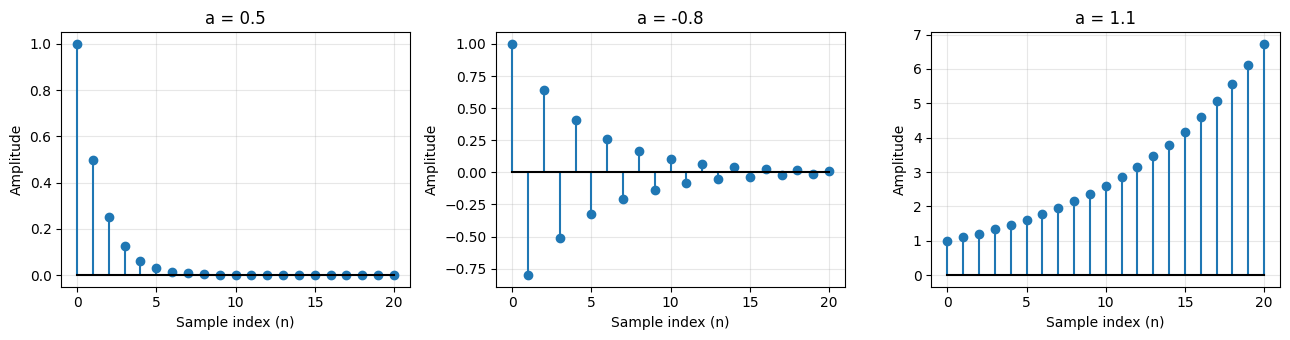

In [19]:

n = np.arange(0, 21)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, a in zip(axes, a_values):
    x = a ** n

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

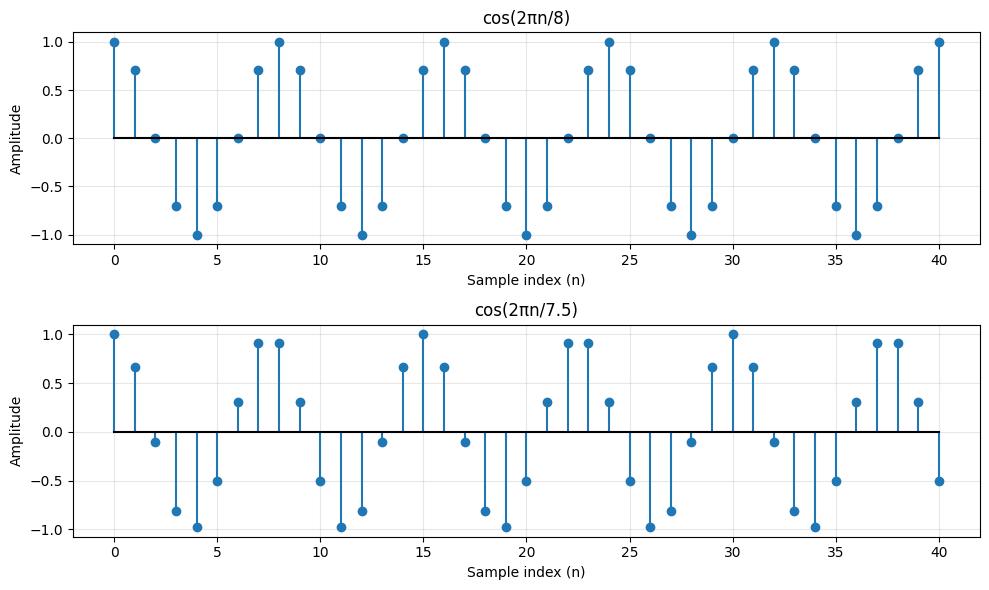

In [20]:

n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("Sample index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("Sample index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Discussion: Periodicity of the Cosine Signals

A discrete-time cosine signal is periodic if it repeats after a positive integer number of samples, N, such that x(n + N) = x(n).

For the first signal:

x₁(n) = cos(2πn/8)

The fundamental period is N = 8 samples.

For the second signal:

x₂(n) = cos(2πn/7.5)

Since 1/7.5 = 2/15, the fundamental period is N = 15 samples.

**Conclusion:**

Both cosine signals are periodic. The first signal repeats after every 8 samples, while the second repeats after every 15 samples. This shows that the two signals have different fundamental periods.

## Task 1.3 — Recording and Processing an Audio Signal

### Objective

Capture a short voice recording and use Python to process the audio data. The task involves reading the WAV file, checking the number of audio channels, converting stereo audio to mono when required, and normalizing the signal amplitude. The resulting audio waveform will then be displayed for analysis.

The recorded audio is saved as `my_voice.wav` in the same folder as the Jupyter Notebook.

### Python Implementation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

fs = 48000 Hz, duration = 3.84 s, samples = 184320


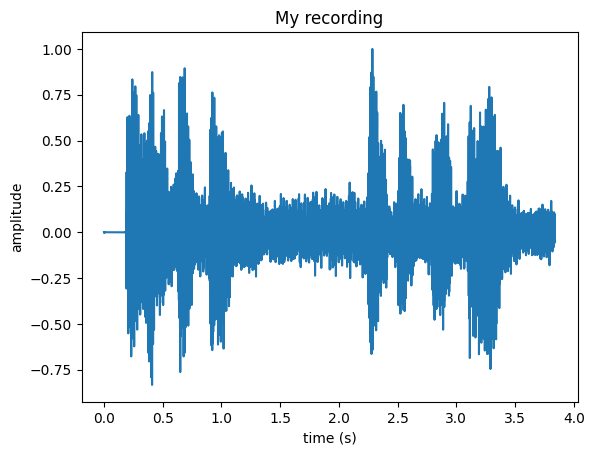

In [10]:

import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x / np.max(np.abs(x))

else:
    # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs

print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

In [11]:

from IPython.display import Audio, display

display(Audio(x, rate=fs))

### Discussion

The audio recording was read successfully into Python using SciPy. The sampling frequency (`fs`) indicates how many audio samples are captured in one second, while the recording duration is obtained by dividing the total number of samples by the sampling frequency.

When the recording contained two channels (stereo), they were combined by calculating their average to obtain a single-channel (mono) signal. Amplitude normalization was then applied to scale the signal so that its maximum absolute value was 1, assuming the recording was not silent.

The waveform visualization provides a view of the signal amplitude over time. It helps show how the recorded voice changes throughout the recording.

## Laboratory Analysis Questions

### Question 1
How many samples are required to record a one-minute mono audio signal at a sampling rate of 44,100 Hz?

**Answer:**

The number of samples is calculated using:

Number of samples = Sampling rate × Duration

= 44,100 × 60

= **2,646,000 samples**

Therefore, a one-minute mono recording at 44,100 Hz contains 2,646,000 samples.

### Question 2
Why is a stem plot appropriate for displaying discrete-time signals?

**Answer:**

A stem plot is appropriate because discrete-time signals consist of individual samples at specific integer time indices. It displays each sample separately, making it easy to identify the amplitude and position of every sample.

### Question 3
Why is an exponential signal with a = 1.1 not BIBO stable?

**Answer:**

For a discrete-time system to be BIBO stable, its impulse response must be absolutely summable.

For the exponential signal:

$$
h(n) = (1.1)^n u(n)
$$

The signal increases as n increases because 1.1 is greater than 1. Therefore, its absolute sum does not converge to a finite value.

Consequently, the system is not BIBO stable.

## AI-use Statement

**AI tool:** ChatGPT.

**Areas of assistance:** I consulted ChatGPT for clarification of certain Digital Signal Processing concepts and guidance when addressing a Python warning. It also helped me improve the presentation and clarity of selected notebook explanations.

**Work validation:** I ran the practical code in Jupyter Notebook and assessed the outputs by reviewing the signal plots, checking the audio recording information and listening to the processed recording. I also reviewed the calculations to ensure their accuracy.

**Personal understanding:** I have reviewed the laboratory exercises and understand the code, processing steps and results presented in my submission.

## GitHub Repository

The source code and laboratory work for this module are maintained in the following repository:

https://github.com/felix202422/COU07506-labs